# Workshop 1 - Sturdy-Octo-Disco-Adding-Sunglasses-for-a-Cool-New-Look
## Name : Pragatheeshraaj D
## Register number : 212224230199

In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

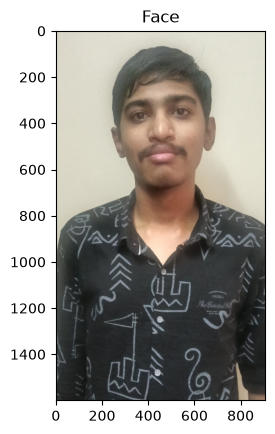

In [2]:
# Load the Face Image
faceImage = cv2.imread('pragatheeshraaj.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [3]:
faceImage.shape

(1600, 907, 3)

In [4]:
#resized_faceImage.shape
faceImage.shape

(1600, 907, 3)

Text(0.5, 1.0, 'glassPNG')

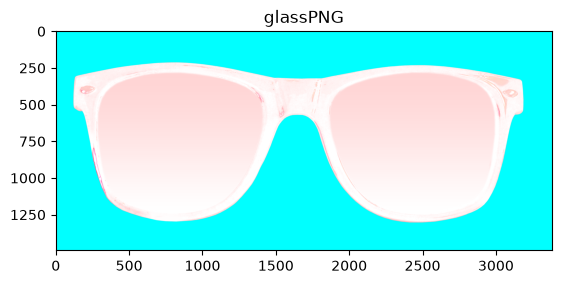

In [5]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglass-png-aviator-sunglass-png-clipart-3381.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [12]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(720, 800))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(800, 720, 4)


In [13]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

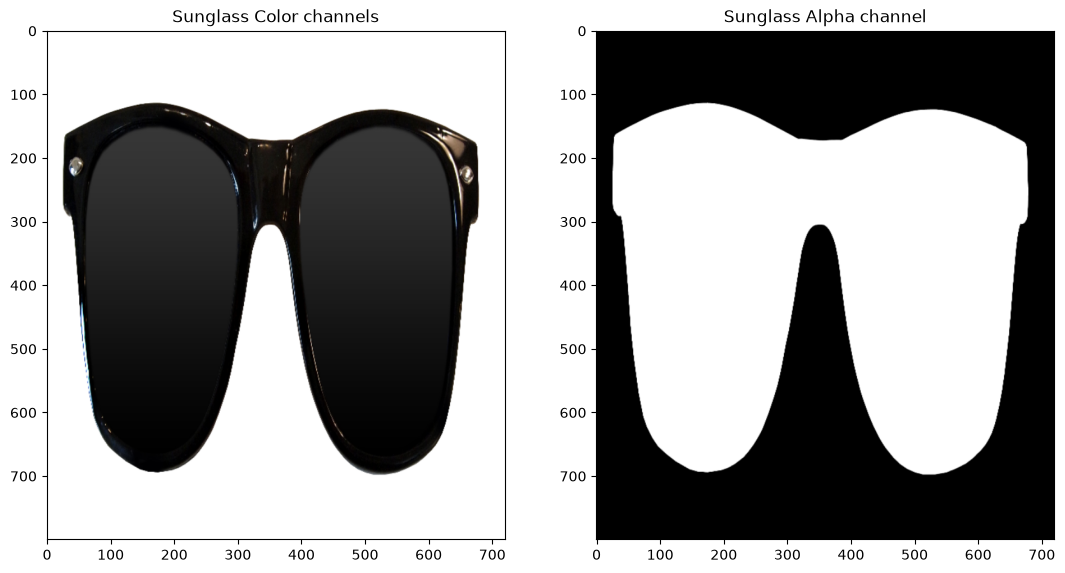

In [14]:
# Display the images for clarity
plt.figure(figsize=[13,40])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

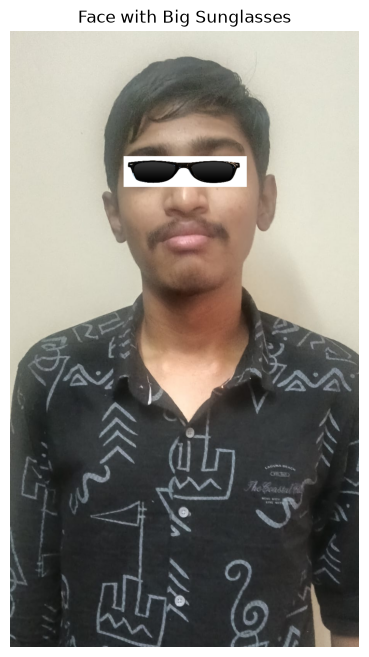

In [22]:
# Make a copy of the face image
faceWithGlassesNaive = faceImage.copy()

# Resize sunglasses to a bigger size
glass_resized = cv2.resize(glassBGR, (320, 80))

# Position sunglasses over both eyes
# Position sunglasses over both eyes
x = 295
y = 325

h, w = glass_resized.shape[:2]

# Overlay sunglasses on the face
faceWithGlassesNaive[y:y+h, x:x+w] = glass_resized

# Display the result
plt.figure(figsize=(6, 8))
plt.imshow(cv2.cvtColor(faceWithGlassesNaive, cv2.COLOR_BGR2RGB))
plt.title("Face with Big Sunglasses")
plt.axis("off")
plt.show()

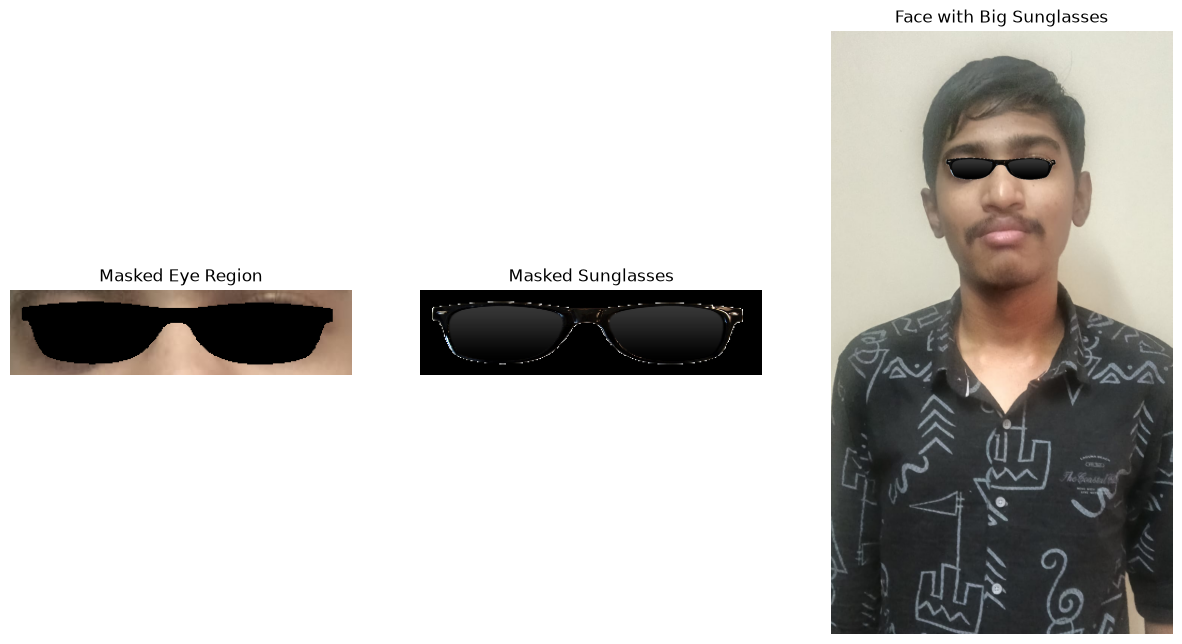

In [25]:


import cv2
import numpy as np
import matplotlib.pyplot as plt

# Set bigger sunglasses size and position
x, y = 295, 325
w, h = 320, 80

# Resize sunglasses and mask
glass_resized = cv2.resize(glassBGR, (w, h))
mask_resized = cv2.resize(glassMask1, (w, h))

# Convert mask to binary values: 0 or 1
mask_resized = np.uint8(mask_resized > 0)

# Create a 3-channel mask
glassMask = cv2.merge((mask_resized, mask_resized, mask_resized))

# Make a copy of the face image
faceWithGlassesArithmetic = faceImage.copy()

# Extract the eye region
eyeROI = faceWithGlassesArithmetic[y:y+h, x:x+w]

# Check dimensions
assert eyeROI.shape == glass_resized.shape == glassMask.shape

# Mask the eye region
maskedEye = cv2.multiply(eyeROI, 1 - glassMask)

# Mask the sunglasses
maskedGlass = cv2.multiply(glass_resized, glassMask)

# Combine both regions
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Place sunglasses on the face
faceWithGlassesArithmetic[y:y+h, x:x+w] = eyeRoiFinal

# Display results
plt.figure(figsize=(15, 8))

plt.subplot(131)
plt.imshow(cv2.cvtColor(maskedEye, cv2.COLOR_BGR2RGB))
plt.title("Masked Eye Region")
plt.axis("off")

plt.subplot(132)
plt.imshow(cv2.cvtColor(maskedGlass, cv2.COLOR_BGR2RGB))
plt.title("Masked Sunglasses")
plt.axis("off")

plt.subplot(133)
plt.imshow(cv2.cvtColor(faceWithGlassesArithmetic, cv2.COLOR_BGR2RGB))
plt.title("Face with Big Sunglasses")
plt.axis("off")

plt.show()


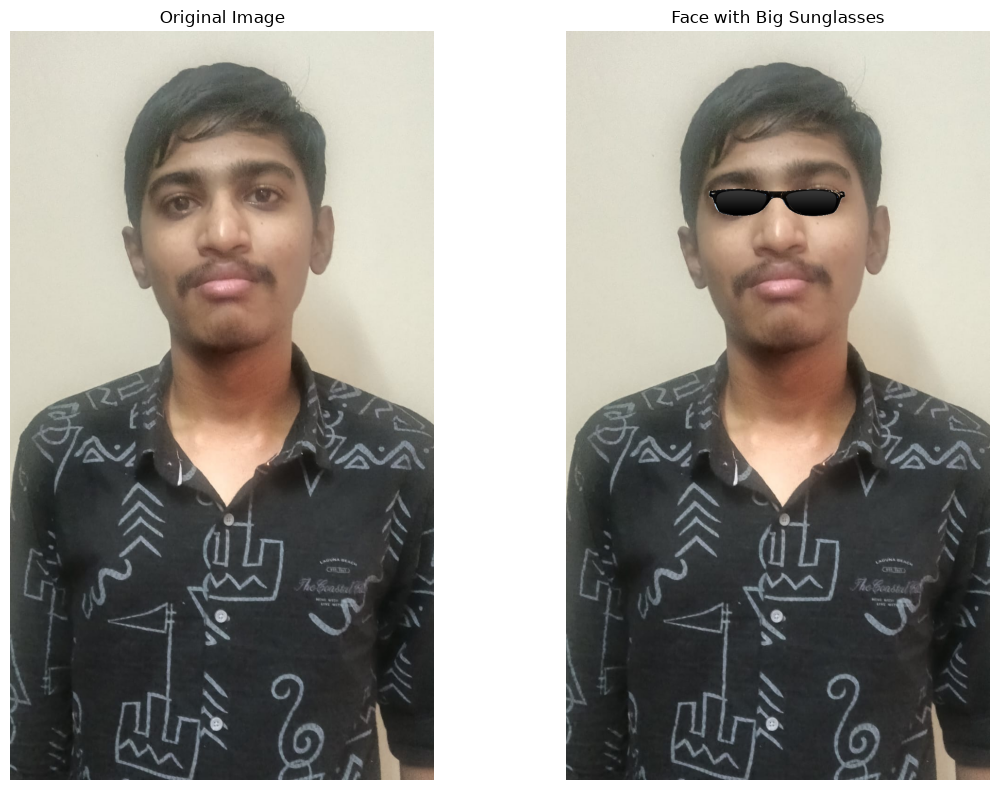

In [29]:

# Replace the eye ROI with the output from the previous section
faceWithGlassesArithmetic = faceImage.copy()

# Use the same coordinates as the previous section
x, y = 295, 325
h, w = eyeRoiFinal.shape[:2]

# Place sunglasses over both eyes
faceWithGlassesArithmetic[y:y+h, x:x+w] = eyeRoiFinal

# Display the final result
plt.figure(figsize=(12, 8))

plt.subplot(121)
plt.imshow(cv2.cvtColor(faceImage, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(122)
plt.imshow(cv2.cvtColor(faceWithGlassesArithmetic, cv2.COLOR_BGR2RGB))
plt.title("Face with Big Sunglasses")
plt.axis("off")

plt.tight_layout()
plt.show()
